![image.png](week10-banner.svg)

![image.png](multimodal-course-outline.svg)

# 学习完课程之后，我们会尝试搭建一个我们自己的小尺寸多模态模型
参考：https://nexa.ai/blogs/omni-vision

![image.png](multimodal-llm-diagram.svg)

![image.png](vision-understanding-concept.svg)

### **说明：本文中代码作解释说明用，实际运行见多模态模型实战**

# 1、卷积神经网络

<div style="font-size:180%; color:red;">
  <strong>在 Transformer 中，我们如何将文字转化为计算机能识别的语义？</strong><br><br>
</div>

<div style="font-size:180%; color:red;">
  <strong>所有的神经网络都在做一件事，把文字、图片、视频。。。变为向量表达</strong><br><br>
</div>


下面用一个通俗易懂的“猫分类”小任务来讲解卷积神经网络（Convolutional Neural Network, CNN）
---

## 1.1. 什么是卷积神经网络？

CNN（卷积神经网络）是一种专门用来处理像素数据（如图像、视频等）的神经网络结构。它最大特点是通过「卷积」操作，可以自动学习图片中的局部特征（比如边缘、角、颜色块等），再逐层综合这些局部特征，最终完成图像分类、目标检测等任务。

传统的全连接神经网络（比如 MLP）如果直接处理图像，会面临参数量过大的问题，而且难以捕捉到图像的「空间局部结构」。CNN 则通过「卷积核（滤波器）」滑动提取图像的局部信息，大幅减少参数量，并且更有效地专注图像的局部特征。



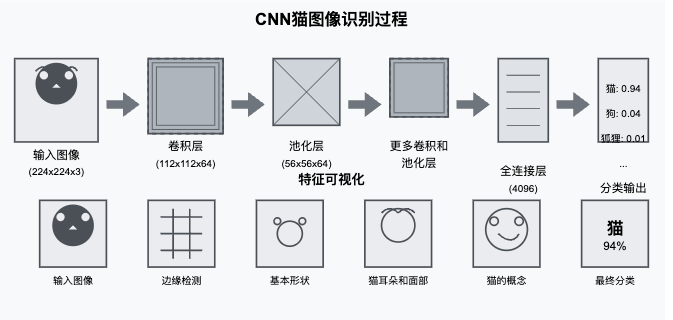

## 1.2. 小任务：看图识猫

### 1.2.1 任务背景
假设我们想训练一个模型，让它可以识别图片里有没有“猫”。我们就需要把很多图片（有的包含猫，有的不包含猫）输入给一个 CNN 模型进行训练，模型学会怎样在图片中找到代表猫的线索——比如猫耳朵的形状、猫眼睛的特征、胡须的样子等等。

### 1.2.2 第一步：图像的局部特征提取

1. **卷积核（滤波器）类似于一个小窗口**  
   - 想象你有一个小“放大镜”，它一次只看图片中的一小部分（例如 3×3 或 5×5 大小的小区域）。
   - 这个小“放大镜”会在整张图片上“滑动”，每次都对所看到的这块小区域做运算，提取某种特定特征，例如检测哪里有轮廓、斜边、猫的毛发纹理等。

2. **卷积核自动学习特征**  
   - 不需要我们手工告诉它什么是“边缘”“圆形”“猫耳朵”，只要我们给大量的带标签图片，CNN 在训练过程中就会“自己”学到一组能够识别关键特征的卷积核。
   - 在初始阶段，卷积核提取的特征可能很基础（如水平/垂直边缘），到了后面几层，CNN 结合低层的特征，提炼出更高级的概念（如猫耳朵、猫眼睛、胡须等）。

### 1.2.3 第二步：特征汇总与分类

1. **池化（Pooling）进一步简化数据**  
   - 在某些层，会用一个叫“池化”的操作（最大池化或平均池化）来把特征图缩小。它可以把相邻特征点合并，比如只保留某个局部区域内最大的响应值，用更少的数据保留重要信息，减轻模型计算量，同时也带来一定的平移不敏感。

2. **全连接层进行最终分类**  
   - 在网络最后，会把各个卷积层输出的特征图“摊平”并送入全连接层（类似传统神经网络），进行最后的分类，比如判断是“猫”还是“非猫”。
   - 全连接层会综合所有提取到的特征信息，给出最终概率：比如“这张图里 90% 可能是猫，10% 可能不是猫”。



## CNN整体流程

![image.png](cnn-architecture.svg)

## 卷积

不同应用场景下，图像的像素分辨率可能差别很大，常见的有以下几类示例：

1. **计算机视觉/深度学习中的输入图像**  
   - 一般会对图片进行预处理或缩放，常见的训练分辨率有：  
     - 224×224（ResNet、VGG 等常用模型的输入大小）  
     - 299×299（Inception 系列模型）  
     - 512×512（一些更高分辨率需求的模型）

2. **显示器/屏幕常见分辨率**  
   - 720p：1280×720  
   - 1080p：1920×1080  
   - 2K：2560×1440  
   - 4K：3840×2160  

3. **手机相机/数码相机照片**  
   - 手机照片常见分辨率在 3000×4000、4000×6000 甚至更高  
   - 专业相机可能达到上千万像素以上，对应的分辨率也会更高
  
在**计算机视觉**中，图像通常使用**8 位**（即 1 个字节）来表示每个通道的像素值，这意味着每个通道的取值范围是 **0 ～ 255**。具体说明如下：

1. **灰度图（单通道）**  
   - 只有一个通道，像素值范围在 0～255 之间  
   - 0 表示纯黑，255 表示纯白

2. **RGB 彩色图（3 通道）**  
   - 分别表示红（R）、绿（G）和蓝（B）三个通道  
   - 每个通道像素值范围同样是 0～255  
   - 一个像素点会由 (R, G, B) 三个分量组成

3. **输入到神经网络的处理**  
   - 在训练深度学习模型时，常常会将原始的 0～255 整数像素值**归一化**或**标准化**，以便网络更好地收敛。例如：  
     - 归一化到 \[0, 1\] 区间  
     - 减去均值再除以标准差（常用在一些预训练模型中，如 ImageNet）

此外，在某些医学图像或专业图像处理中，也可能使用 **16 位**或更高位深度来表示像素值，这样像素值范围会更大，但最常见的依然是 8 位表示的 0～255 区间。

![image.png](convolution-example.svg)

## 池化

详细解释池化操作，包括数字和计算过程。

### 池化操作详细解释

池化是CNN中的另一个关键操作，它主要用于减少特征图的空间尺寸，从而减少网络参数和计算量，同时保留重要特征信息。下面通过具体例子详细讲解池化的工作原理。

### 池化的基本概念

池化操作通常有两种主要类型：
- **最大池化(Max Pooling)**：取窗口内的最大值
- **平均池化(Average Pooling)**：计算窗口内所有值的平均值


### 池化操作的意义

1. **降维**：减少特征图的尺寸，降低计算复杂度
2. **提取主要特征**：
   - 最大池化关注区域内的最显著特征（如边缘、纹理的最强部分）
   - 平均池化考虑区域内的整体特征
3. **提供位置不变性**：对输入的微小位移不敏感，增强模型的鲁棒性
4. **防止过拟合**：通过减少参数数量，降低模型复杂度

### 常见参数设置

- 池化窗口大小：常用2×2或3×3

通过卷积和池化操作的结合，CNN能够逐层提取和抽象图像的特征，建立起层次化的特征表示，为图像识别和理解奠定基础。

![image.png](pooling-explanation.svg)

这种"越做越小"的模式有几个优点：

- 减少计算量和参数数量
- 增加感受野（每个神经元能"看到"的原始输入区域）
- 帮助网络学习层次化特征表示

典型的CNN架构（如LeNet、AlexNet、VGG）都遵循这种模式，即通过多次卷积和池化操作，将输入图像转化为更小、更深的特征图，最后通过全连接层进行分类。


## 展平和全链接

![image.png](flatten-fc-layers.svg)

### 训练过程

1. **数据准备：** 收集“包含猫的图片”和“不包含猫的图片”，贴上标签（猫 / 非猫）。
2. **正向传播：** 把图片输入 CNN，每个卷积核在一张张图片上滑动，提取特征，得到预测结果。
3. **损失函数：** 根据预测结果与真实标签的差异，计算误差（例如交叉熵损失）。
4. **反向传播：** 通过梯度下降等优化方法，不断调整卷积核的参数，让它们越来越能正确地“察觉”到猫的特征。
5. **迭代训练：** 反复对整个训练集做上述操作，直到模型收敛、准确率提高为止。

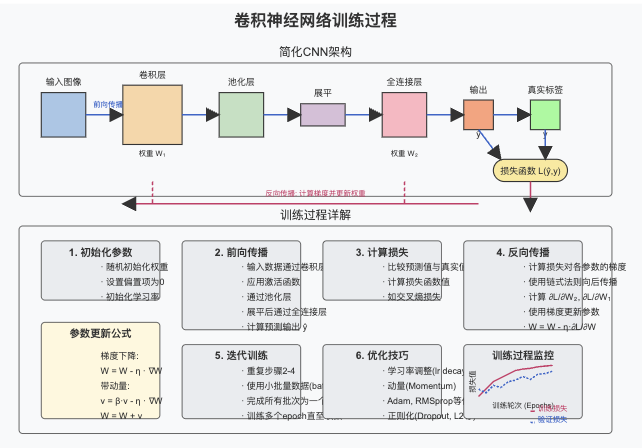

用简单的代码来看看 CNN 的结构

In [78]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # 第一个卷积层，输入通道=3（RGB 三通道图像），输出通道=16，卷积核大小=3
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1)
        
        # 第二个卷积层，输入通道=16，输出通道=32，卷积核大小=3
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        
        # 全连接层，将卷积层提取的特征映射到 10 个输出类别（例如假设要分 10 类）
        self.fc1 = nn.Linear(32 * 8 * 8, 10)  
        # 注意上面 32 * 8 * 8 这个数字要根据池化后特征图的尺寸而定

    def forward(self, x):
        # 经过第一层卷积，然后 ReLU 激活，再最大池化
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)  # 2x2 池化

        # 经过第二层卷积，然后 ReLU 激活，再最大池化
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)  # 再次 2x2 池化
        
        # 将特征图展平
        x = x.view(x.size(0), -1)
        
        # 最后全连接层进行分类
        x = self.fc1(x)
        return x


model = SimpleCNN()
print(model)

# 假设我们有一批大小为 (batch_size=4, 通道数=3, 高度=32, 宽度=32) 的图像
sample_input = torch.randn(4, 3, 32, 32)
output = model(sample_input)
print("输出维度：", output.shape)
print("输出：", output)



SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=2048, out_features=10, bias=True)
)
输出维度： torch.Size([4, 10])
输出： tensor([[-0.2060, -0.1312, -0.2391,  0.2498,  0.1006,  0.0493, -0.1221, -0.4581,
         -0.2169,  0.2261],
        [-0.2024, -0.1095, -0.3484,  0.2970,  0.2867, -0.0388, -0.1711, -0.4915,
         -0.1330,  0.0302],
        [-0.2352, -0.1100, -0.1553,  0.2368,  0.1917,  0.0814, -0.1680, -0.5898,
         -0.2240,  0.1019],
        [-0.2063, -0.2853, -0.2959,  0.3989,  0.2166,  0.0316, -0.1610, -0.6074,
         -0.1661,  0.2131]], grad_fn=<AddmmBackward0>)


![image.png](feature-vector-extraction1.svg)

# 2. ViT

![image.png](vision-understanding-concept.svg)

https://arxiv.org/pdf/2010.11929

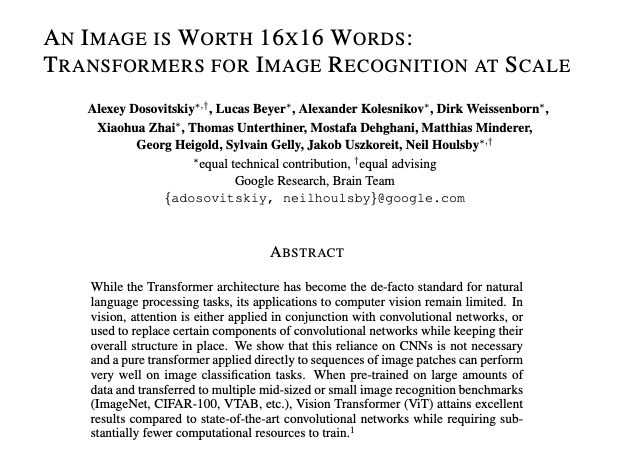

<div style="font-size:180%; color:red;">
  <strong>ViT奠定了现在多模态大模型的基础</strong><br><br>
</div>

![image.png](transformer-conclusions.svg)

## 那么如何把图片转化为文本序列呢？

## 2.1 将一个图片切割为N*N的batch

一个像素点表达的信息实在太少，所以切割为不同的相同大小的块，每一个块相当于文本里面的token

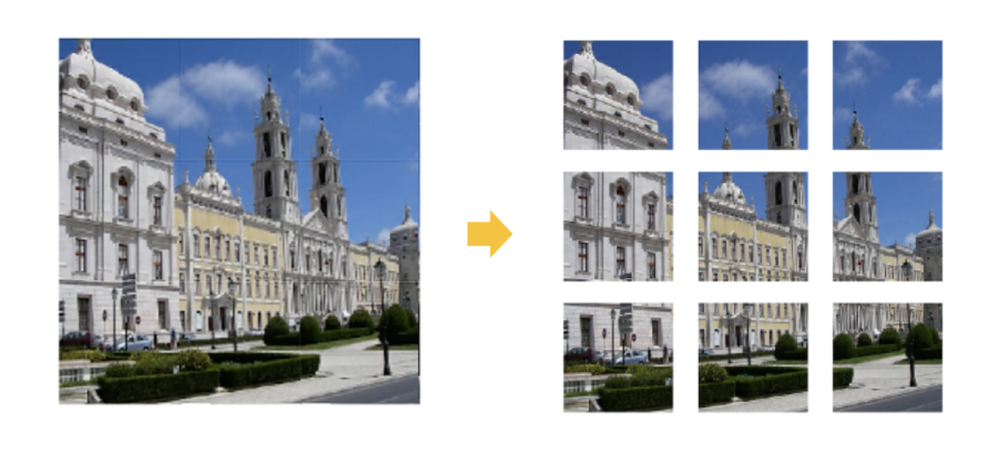

## 2.2 传入encoder only的transformer架构

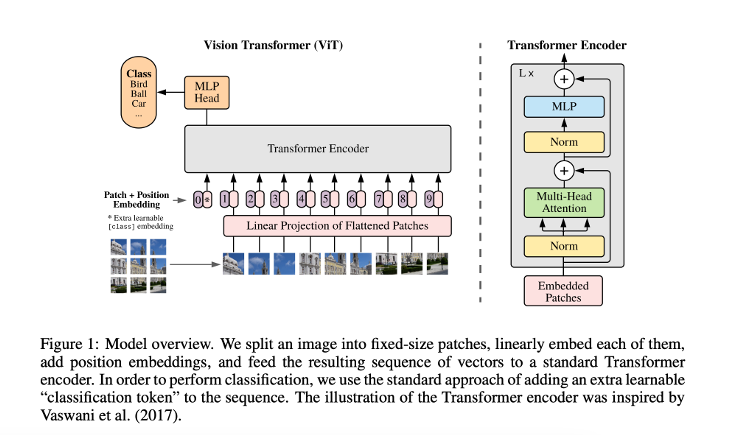

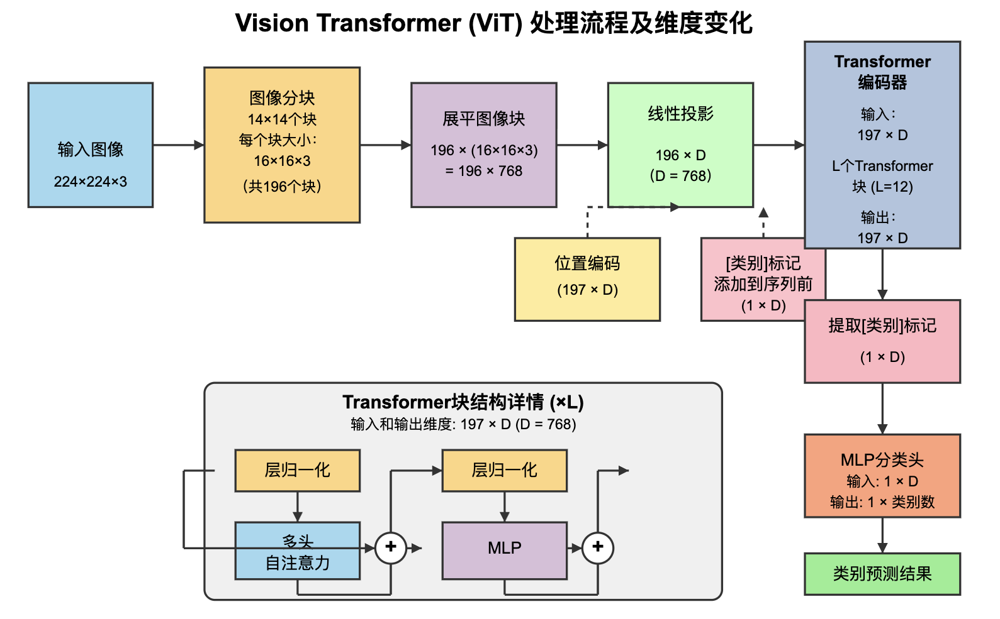

### ViT 处理流程：以224×224像素图片为例

#### 1. 图像分块 (Patch Extraction)
- 输入图像尺寸：224×224×3 (高×宽×RGB通道)
- 假设使用标准的16×16大小的图像块
- 将图像分成(224÷16)×(224÷16) = 14×14 = 196个块
- 每个块的维度：16×16×3 = 768个像素值

#### 2. 线性投影 (Linear Projection)
- 每个16×16×3的图像块被展平成768维向量
- 这些向量通过线性层投影到模型的隐藏维度（假设为D=768）
- 结果：196个维度为768的嵌入向量
- 经过一个线性层（768，1024）的线性层编码

#### 3. 位置嵌入 + 类别嵌入
- 为196个图像块嵌入添加位置编码（每个位置编码也是1024维）
- 在序列开头添加一个特殊的可学习的[class]标记（图中标为"0*"），此标记将用于最终分类
- 最终输入序列长度：196 + 1 = 197个标记，每个标记为1024维

#### 4. Transformer编码器处理
右侧图显示了Transformer编码器的详细结构，输入为已嵌入的图像块序列:
1. 序列进入多层Transformer块（假设L=12层）
2. 每个块包含:
   - 标准化层(Norm)
   - 多头自注意力机制(Multi-Head Attention)，通常8或12个头
   - 残差连接(+)
   - 另一个标准化层
   - 多层感知机(MLP)网络
   - 另一个残差连接

#### 5. 分类输出
- 从最终Transformer层输出中提取[class]标记（即位置0对应的嵌入）
- 该嵌入通过MLP头（图中左上方的"MLP Head"）进行处理
- MLP头输出图像的类别预测（例如：Bird, Ball, Car等）

#### 数据维度的变化总结
1. 输入图像: 224×224×3
2. 分块后: 196个16×16×3的块
3. 线性投影后: 196个1024维向量
4. 添加[class]标记后: 197个1024维向量
5. Transformer编码器处理: 保持197×1024的维度，但信息通过自注意力机制在标记间流动
6. 分类: 提取1024维的[class]标记，通过MLP头输出最终类别


**【补充】图像分块的卷积实现：**
输入：

图像尺寸为：
224
×
224
×
3
224×224×3 (高×宽×通道数)。

卷积参数设定：

使用卷积核数量：
1024
1024 个（对应1024个输出通道）。

卷积核尺寸设为图像块的大小：
16
×
16
16×16。

步长（stride）：16。

padding方式："valid"（即不进行任何补零）。

结果：

通道数：1024（卷积核数量）

最终卷积结果为：
14
×
14
×
1024
14×14×1024。

## 2.3 结果评估

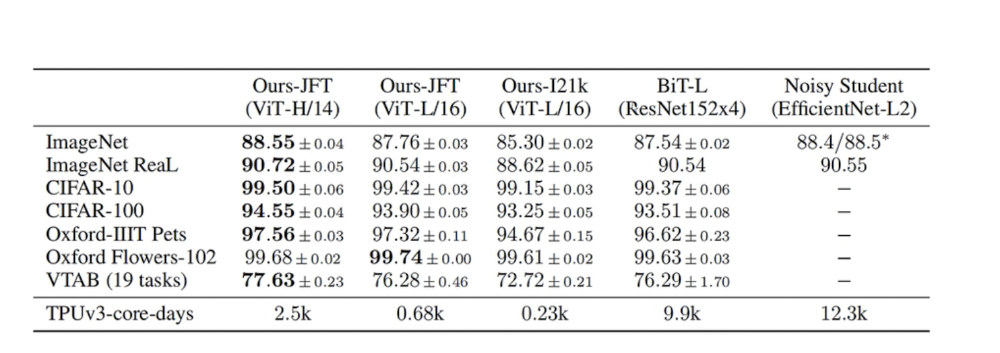

## 2.4 其他讨论

### 位置编码

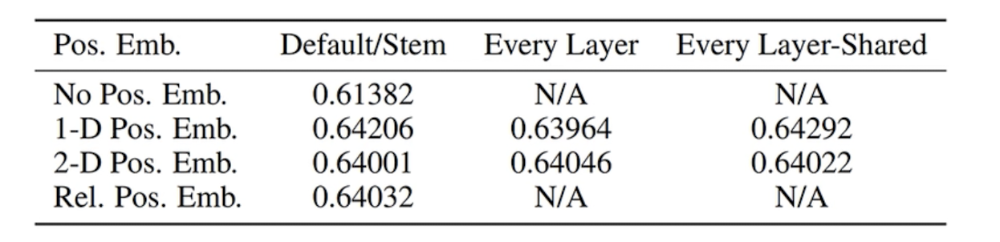

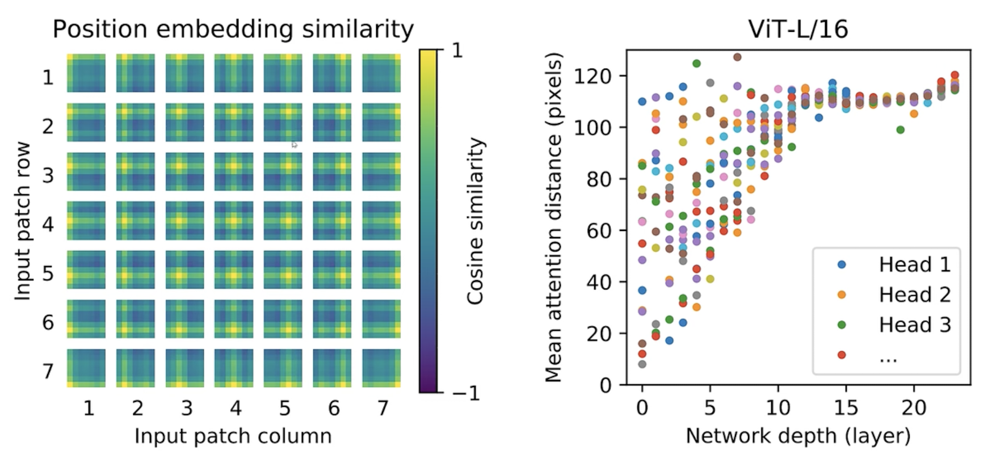

**关键结论：**

1. **位置编码类型对性能的影响**：
   - 无位置编码（No Pos. Emb.）的性能最低，仅为0.61382，这说明位置编码对ViT模型的性能提升具有明显作用。
   - 采用1-D位置编码（1-D Pos. Emb.）和2-D位置编码（2-D Pos. Emb.）以及相对位置编码（Rel. Pos. Emb.）后，模型性能显著提高，三种方法的性能（0.64001至0.64292）较为接近，表明位置编码的具体方式影响不大，但使用位置编码是必要的。

2. **感受野**：

**在Transformer的浅层中，部分注意力头已经开始关注远距离的信息**，这意味着ViT可以在模型的初始阶段就建立图像中远距离区域之间的联系，从而具备强大的**全局建模能力**。

而相比之下，**CNN的感受野是局部扩展的**，必须通过多层卷积叠加才能逐渐覆盖整个图像，因此在浅层阶段更多关注的是局部特征，难以捕捉长距离依赖。

这一差异使得ViT在处理需要全局上下文理解的任务（如物体识别、关系建模等）中，具有更大的潜力与表现优势。


### 数据集的影响

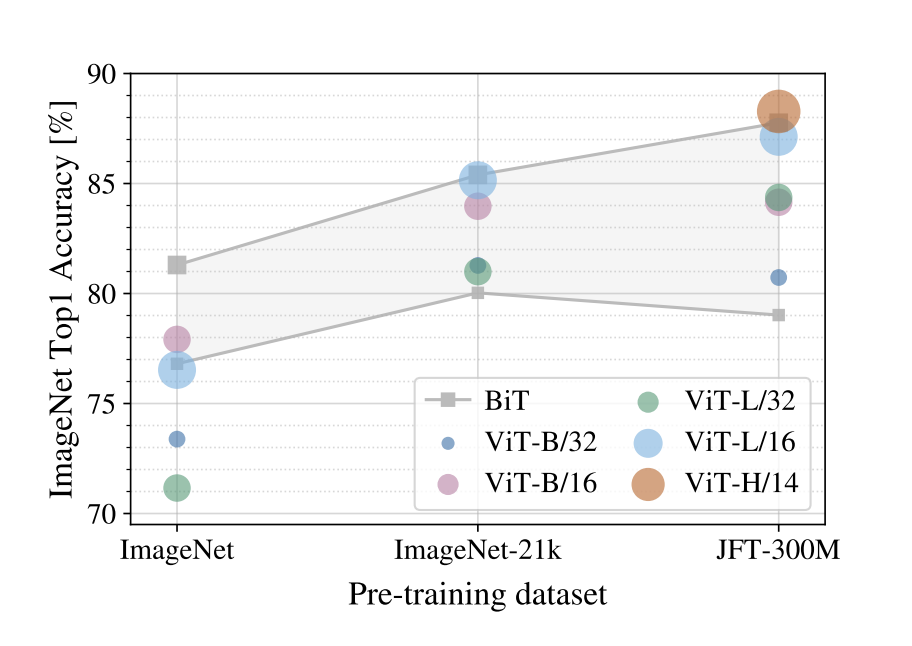

- ViT在小规模数据集上不如ResNet，在中等规模数据集上表现相当，而在大规模数据集上则明显优于ResNet。
- 大数据 + 大模型 = 高性能的典型趋势，也说明了ViT类模型随着数据量和模型规模的增加能带来显著的精度提升。

# 3. Clip

![image.png](vision-understanding-concept1.svg)

### 所以要数据足够多，而且不依赖标注

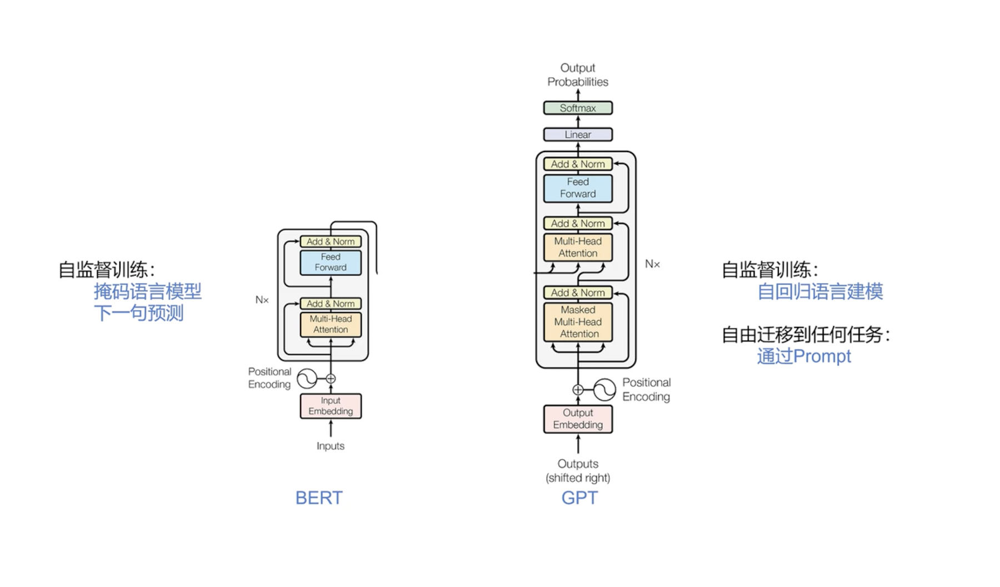

## 训练数据

### 4亿个文本对

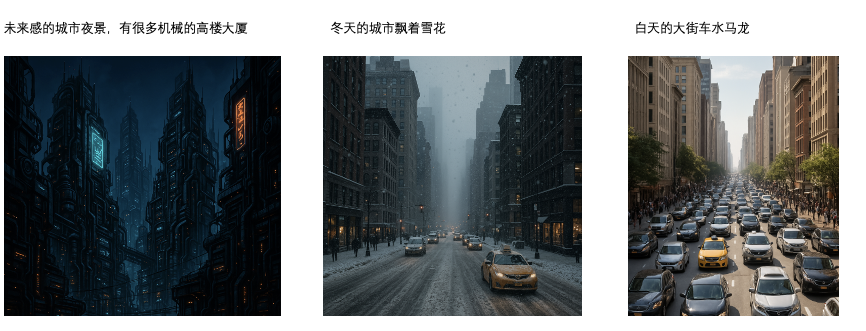

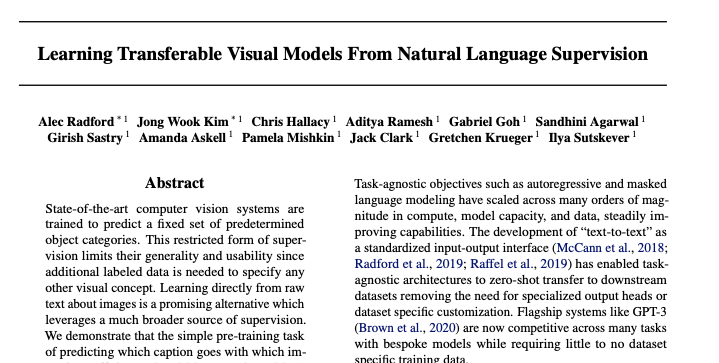

### 💡论文标题意思：
> **从自然语言监督中学习可迁移的视觉模型**

也就是说，他们用“文字描述”来教电脑看图识物，而不是靠传统的数据标签。

---

### 📌摘要（Abstract）通俗解释：

1. **传统视觉模型怎么做的？**
   - 以前的计算机视觉模型是用成千上万张打了标签的图片来训练的，比如“这是一只猫”、“这是辆车”。
   - 这种方式的问题是：它只能识别你训练时给它的那些类别，要让它识别新的东西就得重新训练。

2. **那他们的方法有啥不同？**
   - 他们让电脑直接从“图+文字描述”的对照中学习，比如“一只穿毛衣的狗”、“一个人在山上滑雪”。
   - 这样模型就可以学会“理解图片和语言之间的关系”，而不是死记硬背分类标签。

3. **有啥好处？**
   - 学会这种通用理解后，模型可以在没见过的新任务中也表现得不错，比如：搜索图片、分类图片、给图片配标题等等。
   - 不需要专门为每个任务重新训练模型，节省了大量的数据和人力。

---

### 🧠打个比方：

以前的模型像是一个死记硬背的学生，只能答他学过的题；
而 CLIP 更像是一个理解能力强的学生，学会了“怎么读题”和“怎么理解图片”，所以碰到没见过的题也能做。


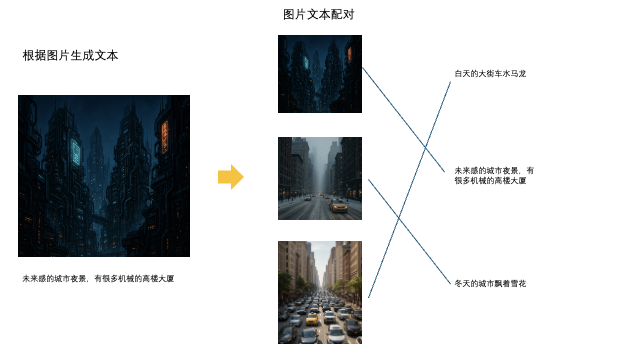/

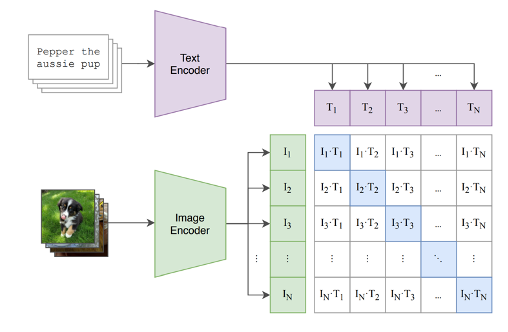


## 3.1 CLIP 是怎么训练出来的？

CLIP 的核心目标是：
> **让模型学会把“图像”和“对应的文字描述”匹配起来**，从而获得一种通用的视觉理解能力。

### a、训练数据来源

CLIP **没有使用手动打标签的数据集**（如ImageNet），而是使用了：
- **4亿对**图像和文字（image-text pairs）来自互联网（比如网页、文章中配图和配文）。

这些图像-文字对来自真实世界，文字描述更自然、更丰富。

---

### b、模型架构

CLIP 是一个 **双塔模型（dual encoder）**：

| 图像编码器（Image Encoder） | 文字编码器（Text Encoder） |
|-----------------------------|-----------------------------|
| ViT等 | Bert/GPT |
| 把图像转成一个向量表示            | 把文字描述转成一个向量表示         |

目标就是让图像和与之匹配的文字描述的向量**靠得近**，而不匹配的**远离**。

---

### c、训练目标：对比学习（Contrastive Learning）

CLIP 使用 **对比损失（Contrastive Loss）**：

假设你有一批图像 `I₁, I₂, ..., Iₙ` 和文字 `T₁, T₂, ..., Tₙ`，每个图像 `Iᵢ` 正确的文字描述是 `Tᵢ`。

训练的目标是：
- 让 `I₁` 跟 `T₁` 的向量距离最近；
- 让 `I₁` 和 `T₂, T₃...Tₙ` 这些错误的文字距离远。

这个机制可以通过 **InfoNCE loss** 实现，计算图像与文字之间的相似度（通常是 cosine similarity），再用 softmax 做归一化。

#### 换句话说：
- 每一对图像-文字都是一个“正样本”；
- 其余的 `N-1` 对都当作“负样本”；
- 训练过程就是不断地“拉近正样本距离，推远负样本距离”。

---

### d、并行训练细节

为了处理超大规模数据，CLIP 使用了以下训练技巧：

| 技术 | 描述 |
|------|------|
| 多GPU分布式训练 | 使用了256个GPU训练了2周 |
| 预处理和缓存 | 图像先 resize 到统一大小，文字经过 BPE 分词 |
| mixed precision | 使用半精度（float16）加速训练，节省显存 |
| 大batch对比学习 | 每个batch中同时包含多个图文对，用大规模对比信息训练更稳定 |



### 伪代码如下

In [ ]:
# image_encoder  - 图像编码器，例如 ResNet 或 Vision Transformer
# text_encoder   - 文本编码器，例如 CBOW 或 Transformer
# I[n, h, w, c]  - 一批对齐的图像（batch），形状为 [n, 高, 宽, 通道]
# T[n, l]        - 一批对齐的文本，形状为 [n, 文本长度]
# W_i[d_i, d_e]  - 图像特征映射到共同嵌入空间的投影矩阵
# W_t[d_t, d_e]  - 文本特征映射到共同嵌入空间的投影矩阵
# t              - 可学习的温度参数（用于调整相似度分布）

# 提取每种模态的特征表示
I_f = image_encoder(I)     # 输出图像特征，形状 [n, d_i]
T_f = text_encoder(T)      # 输出文本特征，形状 [n, d_t]

# 投影到多模态共享嵌入空间，并进行 L2 归一化，形状为 [n, d_e]
I_e = l2_normalize(np.dot(I_f, W_i), axis=1)  # 图像嵌入
T_e = l2_normalize(np.dot(T_f, W_t), axis=1)  # 文本嵌入

# 计算图文之间的相似度（点积后乘以温度参数），输出形状 [n, n]
logits = np.dot(I_e, T_e.T) * np.exp(t)

# 构造对比学习的对称损失函数
labels = np.arange(n)  # 构造标签，例如 [0, 1, 2, ..., n-1]
loss_i = cross_entropy_loss(logits, labels, axis=0)  # 图像→文本方向的交叉熵损失
loss_t = cross_entropy_loss(logits, labels, axis=1)  # 文本→图像方向的交叉熵损失
loss   = (loss_i + loss_t) / 2  # 平均作为最终损失


![image.png](ai-encoders-diagram.svg)

- 文本编码器仅6300万参数

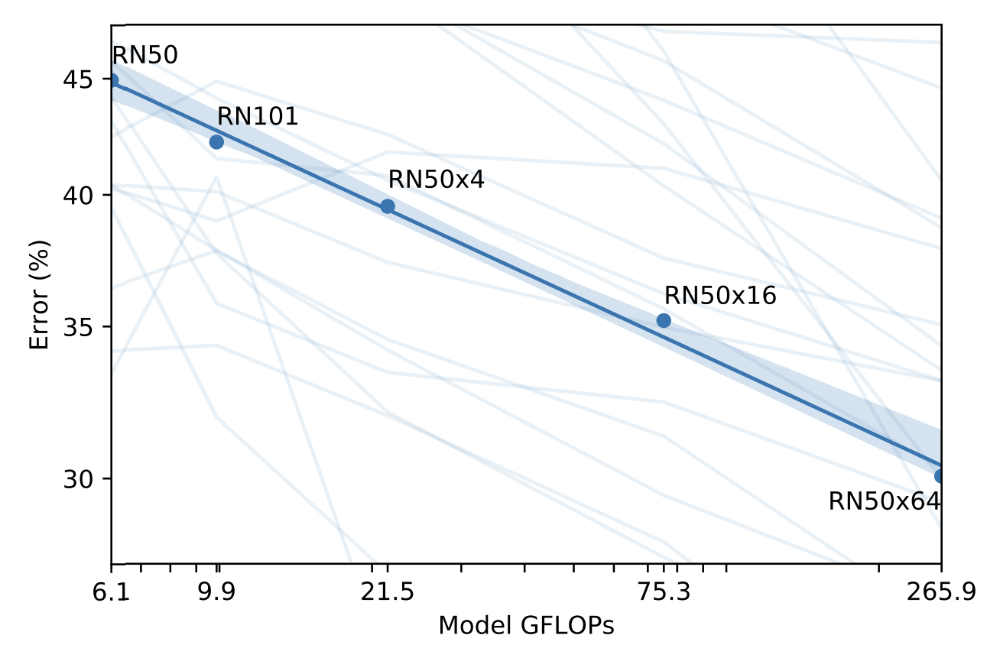

Batch Size 32768

- 数据量足够大：

- 图片编码器和文本编码器都没有预训练。

## 3.2 模型推理与评估

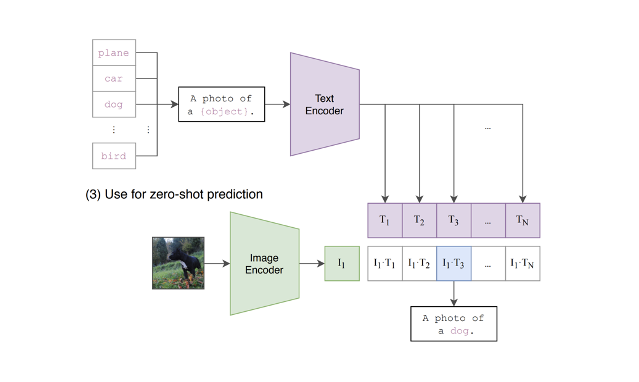

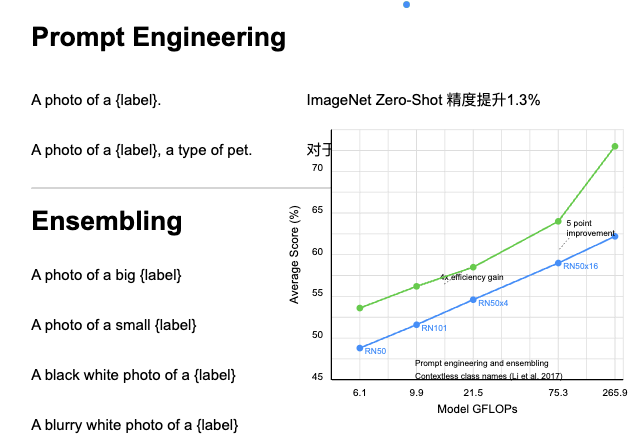

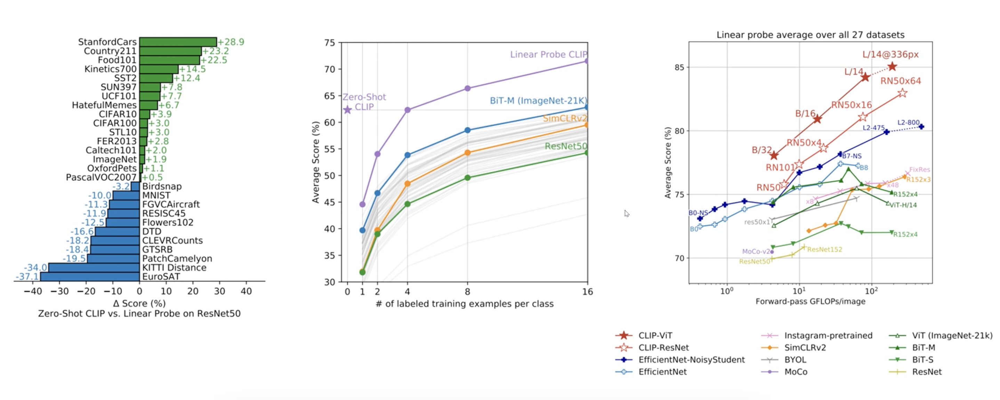

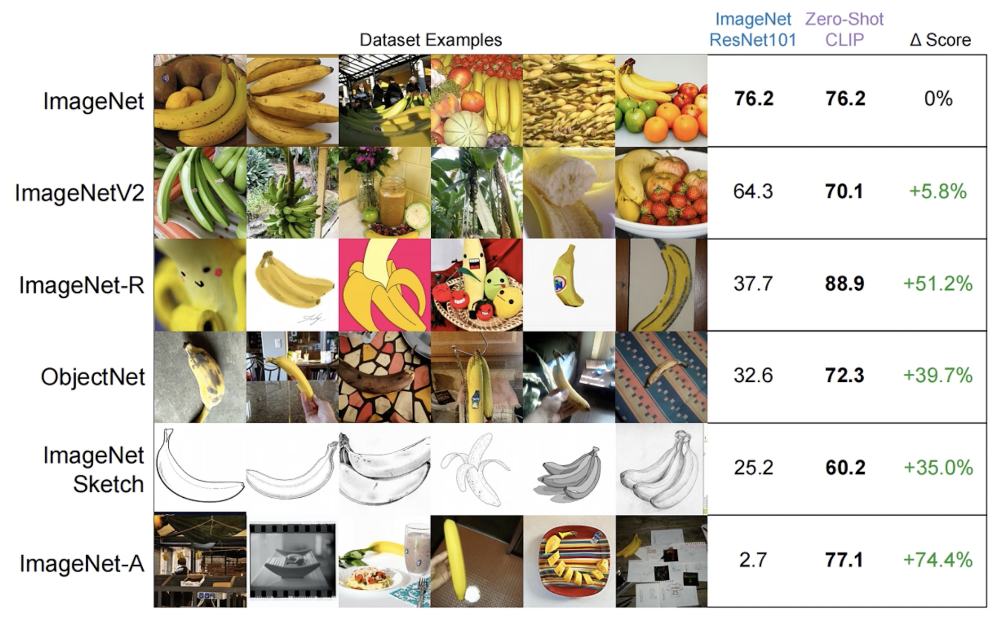

## 3.3 clip的使用

### 3.3.1 Finetune：如何用 CLIP 迁移学习你的任务？

In [ ]:
！pip install git+https://github.com/openai/CLIP.git
！pip install torch torchvision pillow

In [ ]:

#示意代码

import os
import torch
import clip
from PIL import Image

def load_images_from_folder(folder_path):
    """
    给定文件夹路径，加载其中所有图片并返回它们的路径列表。
    """
    img_paths = []
    for filename in os.listdir(folder_path):
        # 简单判断一下后缀是否为常见的图片格式
        if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
            img_paths.append(os.path.join(folder_path, filename))
    return img_paths

def encode_images(image_paths, model, preprocess, device):
    """
    对所有图片进行编码，得到它们的特征向量。
    """
    images = []
    for path in image_paths:
        img = Image.open(path).convert("RGB")
        images.append(preprocess(img))
    
    # 将所有图像张量合并在一起，加速推理
    image_tensor = torch.stack(images).to(device)

    with torch.no_grad():
        image_features = model.encode_image(image_tensor)

    # 对编码后的特征做 L2 归一化（方便直接计算余弦相似度）
    image_features = image_features / image_features.norm(dim=-1, keepdim=True)
    return image_features

def encode_text(text_list, model, device):
    """
    对文本进行编码，得到文本特征向量。
    """
    # 使用CLIP提供的tokenizer处理文本
    text_tokens = clip.tokenize(text_list).to(device)

    with torch.no_grad():
        text_features = model.encode_text(text_tokens)
    
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)
    return text_features

def main():
    # ----- 1. 加载模型 -----
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, preprocess = clip.load("ViT-B/32", device=device)

    # ----- 2. 准备图片数据 -----
    # 假设你有一个文件夹，里面放了若干图片
    folder_path = "path_to_your_image_folder"  # 替换成自己的图片文件夹路径
    image_paths = load_images_from_folder(folder_path)

    # 对文件夹中的所有图片进行编码
    image_features = encode_images(image_paths, model, preprocess, device)

    # ----- 3. 文本编码 -----
    # 示例：我们想查找“黑色猫咪坐在沙发上”
    query_text = ["黑色猫咪坐在沙发上"]
    text_features = encode_text(query_text, model, device)  # [1, embed_dim]

    # ----- 4. 计算相似度并排序 -----
    # 余弦相似度可以通过点乘归一化后的特征来实现
    # image_features shape: [N, embed_dim]
    # text_features shape: [1, embed_dim]
    # 点乘之后得到 [N, 1]
    with torch.no_grad():
        similarities = (image_features @ text_features.T).squeeze(1)  # [N]
    
    # 按照相似度从大到小排序
    sorted_indices = similarities.argsort(descending=True)

    print("根据文本查询：", query_text[0])
    print("搜索结果（按照相似度从高到低）:")
    for idx in sorted_indices:
        img_path = image_paths[idx]
        score = similarities[idx].item()
        print(f"图片: {img_path}, 相似度: {score:.4f}")

main()


### 3.3.2 Finetune：如何用 CLIP 迁移学习你的任务？

CLIP 本质是图文匹配模型，你可以利用它强大的特征提取能力来做：

- 图片分类

- 图文检索

- 多模态对话/问答

文生图（配合其他模块）

👇Finetune 通常有两种方式：

**方式一：冻结 CLIP，只训练上层分类器**

In [ ]:
import torch
from transformers import CLIPModel, CLIPProcessor

#示例代码

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# 冻结 CLIP 本体
for param in model.parameters():
    param.requires_grad = False

# 增加新的分类头（你也可以自己接MLP）
model.classification_head = torch.nn.Linear(model.config.projection_dim, num_classes)


**方式二：端到端微调（Finetune 整个模型）**
- 这适用于你有较多数据，或者任务 domain 和 CLIP 的训练差异比较大时：

In [ ]:
# 不冻结参数，整体finetune
optimizer = torch.optim.Adam(model.parameters(), lr=1e-5)

**示例代码：图像分类任务 Finetune
以“图像分类”为例，我们可以做个小的训练 loop：**

In [ ]:
from transformers import CLIPProcessor, CLIPModel
import torch
from torch.utils.data import DataLoader
from torchvision.datasets import CIFAR10
from torchvision import transforms

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])
dataset = CIFAR10(root="./data", train=True, transform=transform, download=True)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

# 文本标签列表
labels = ["airplane", "automobile", "bird", "cat", "deer", 
          "dog", "frog", "horse", "ship", "truck"]
text_inputs = processor(text=labels, return_tensors="pt", padding=True)

for batch in dataloader:
    images, targets = batch
    inputs = processor(images=images, text=labels, return_tensors="pt", padding=True)

    outputs = model(**inputs)
    logits_per_image = outputs.logits_per_image  # [batch, num_text_labels]
    loss = torch.nn.functional.cross_entropy(logits_per_image, targets)
    
    # backward + optimize...


# 3.4 CLIP的优势

- **利用了丰富的语义作为监督**  
  学习到了很多细节语义特征

- **将图像和文本进行了连接**  
  可以利用文本来查询图像

- **不用预先定义固定类别的标签**  
  通过 Prompt 来查询


# 4、 BLIP

https://arxiv.org/pdf/2201.12086

![image.png](vision-understanding-concept5.svg)

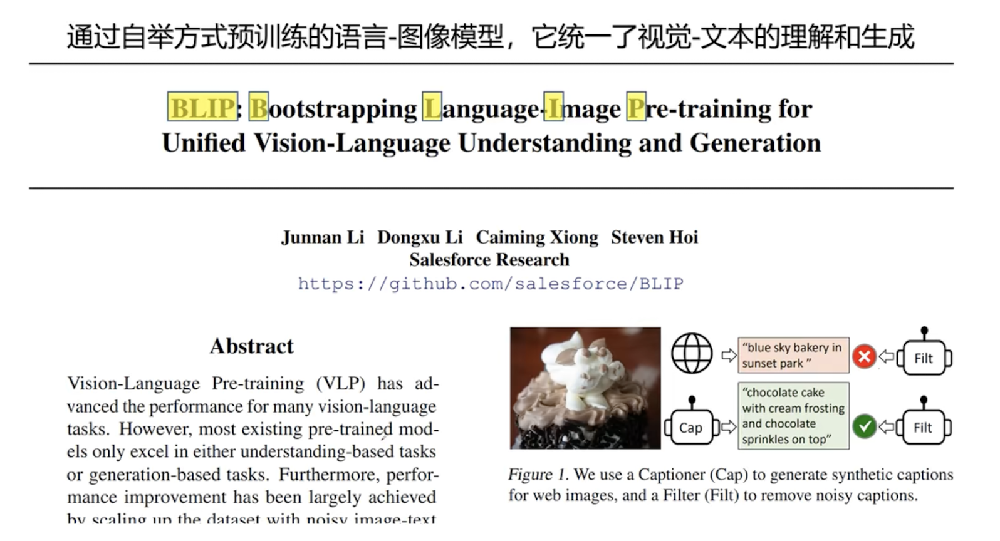

## 问题1:如何解决理解+匹配+生成

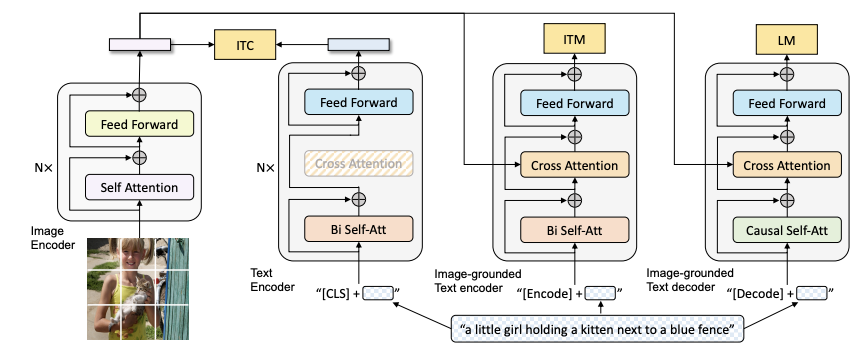

这张图展示的是 **BLIP（Bootstrapping Language-Image Pre-training）** 模型的整体架构，它是一种多模态预训练框架，支持图文匹配、图文生成等任务。BLIP 架构整合了 **视觉编码器**、**文本编码器** 和 **图文交叉模块**，并设计了三种预训练目标：ITC（Image-Text Contrastive）、ITM（Image-Text Matching）和 LM（Language Modeling）。

我们逐块解释：

---

### 图像编码器（Image Encoder）
- 输入是图像（如一个女孩抱着小猫），经过切分为 patch 后输入。
- 使用 Vision Transformer（ViT）进行编码，包含：
  - 多层 **Self Attention + Feed Forward**
- 输出图像的全局表示或 patch 表示，用于下游模块。

---

### 文本编码器（Text Encoder）
- 输入格式：`[CLS] + tokenized text`
- 经过多层 Transformer 编码器：
  - **Bi-directional Self Attention（Bi Self-Att）**：支持整句上下文理解
  - 可选择性地加上 **Cross Attention** 来整合图像特征（图中是虚线表示：可选阶段）
- 输出图文联合表示。

---

### 三个预训练目标

---

#### 1. ITC（Image-Text Contrastive Learning）
- 用于学习图像和文本的全局对齐。
- 输入图像和文本分别由图像编码器和文本编码器编码。
- 计算图像和文本之间的相似度，对比学习目标是：**匹配的图文更相似，不匹配的图文更不相似**。

---

#### 2. ITM（Image-Text Matching）
- 判断给定图文是否匹配（类似于分类任务）。
- 文本经过 **图像引导的编码器（Image-grounded Text Encoder）**，加入了 Cross Attention 来整合图像信息。
- `[CLS]` token 用于判断匹配概率

---

#### 3. LM（Language Modeling）
- 进行图文生成任务（如图像描述）。
- 文本输入是 `[Decode] + tokenized text`，用因果注意力（Causal Self-Att）保证解码器只能看到左边的信息。
- 使用 **图像引导的 Text Decoder**：包含 Cross Attention 将图像信息加入生成流程。
- 可训练成图像描述模型或图文生成模型。

---

### 总体流程总结
- 图像经过视觉编码器，输出特征用于三个任务。
- 文本在不同模块中使用不同的注意力结构：
  - ITC 使用 Bi-Encoder（图像与文本分开编码）
  - ITM 使用 Cross-Encoder（图文交叉编码）
  - LM 使用 Encoder-Decoder（图像编码，文本解码）
- 三种训练任务相辅相成：对齐（ITC）、判断（ITM）、生成（LM），实现语言与图像的深度融合。

---

# “**一套模型适配多种任务**”

- 图文检索（Image-Text Retrieval）
- 图像问答（Visual Question Answering）
- 图像描述生成（Image Captioning）
- 图文匹配（Image-Text Matching）

---

## ✅ 如何满足不同任务需求？

BLIP 是通过**不同的“模式”或“路径”组合**图像编码器与文本模块（Encoder 或 Decoder），实现对不同任务的适配。我们可以将使用方式分为以下几类：

---

### A. **图文检索（Image ↔ Text Retrieval）**
#### ✅ 使用模块：
- 图像编码器（ViT）
- 文本编码器（Bi-Encoder 模式）
- ITC（Image-Text Contrastive）Loss

#### ✅ 工作流程：
- 图像和文本**分别独立编码**成向量（Bi-Encoder结构）
- 用余弦相似度度量图文之间的相似度
- 排序后选出最匹配的图文对

这种结构效率很高，适合大规模检索。

---

### B. **图文匹配（Image-Text Matching, ITM）**
#### ✅ 使用模块：
- 图像编码器
- 图像引导的文本编码器（加 Cross Attention）
- ITM（分类任务）

#### ✅ 工作流程：
- 文本编码器**读取图像特征作为 context**（Cross Attention）
- 利用 `[CLS]` token 输出一个匹配概率
- 用于判断“这张图和这句话是否匹配”

这个任务可以fine-tune用于例如 VQA 的 early stage 过滤。

---

### C. **图像描述生成（Image Captioning）**
#### ✅ 使用模块：
- 图像编码器
- 文本解码器（带 Cross Attention）
- LM 任务（Causal Language Modeling）

#### ✅ 工作流程：
- 图像先编码为视觉特征
- 文本解码器一步步生成句子（自回归），每一步都读取图像信息
- 使用 Masked/Causal Attention 保证生成流动方向

这种方式适合用于生成像 “a dog is playing on the beach” 的描述。

---

### D. **图像问答（VQA）或多轮对话**
（VQA 通常是后续任务 fine-tune，但架构本质支持）

#### ✅ 使用模块：
- 图像编码器
- 图像引导的文本编码器 或 解码器（按需要选用）
- LM 或 ITM 任务（判断or生成）

#### ✅ 工作流程：
- 问题作为输入文本，图像为上下文
- 用 decoder 生成答案，或 encoder 输出匹配（如判断答案是否合理）


## 问题2:如何解决CLIP的训练噪音的问题

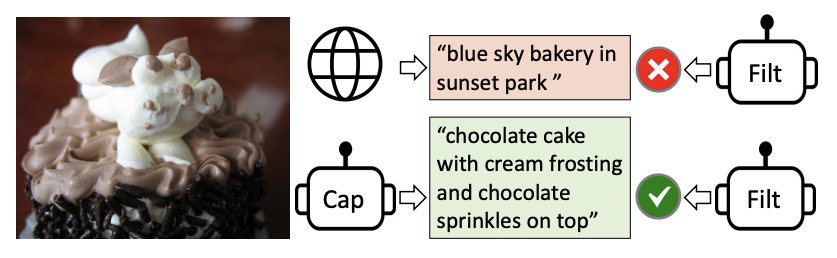

## Caption+Filter

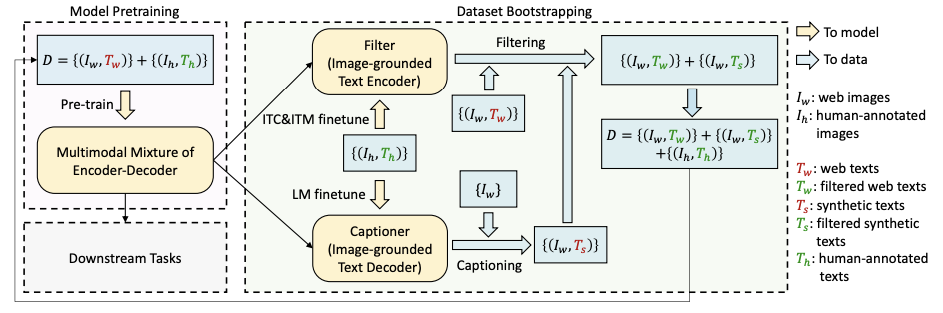

## 训练过程详解

### A. 数据集形式与初始来源

图中最左侧标注了数据集 \(D\)，其中包含：
- \(\{(I_w, T_w)\}\)：从互联网上爬取的（web）图像和其配套文本对（可能噪声较大）；
- \(\{(I_h, T_h)\}\)：人工标注的（human-annotated）图像-文本对（高质量但规模可能相对较小）。

这些图像-文本对共同构成了初始训练数据。

---

### B. 模型预训练（Model Pretraining）

在图的左侧方框里，可以看到“**Multimodal Mixture of Encoder-Decoder**”这一块。这表示 BLIP2 使用了图像编码器与文本编码器/解码器相结合的多模态框架，进行大规模的预训练。总体而言，BLIP2 的核心模型结构会在海量的图文数据上，学到以下能力：

1. **图文对齐（Image-Text Alignment）**：理解图像与文字之间的语义对应关系（例如，图像中是什么、对应文本中描述了什么等）。
2. **多模态信息融合（Multimodal Fusion）**：在模型内部将视觉特征和语言特征进行高效融合，为下游任务提供良好的多模态表征。
3. **语言生成（Text Generation）**：在结合图像的上下文后，生成相应描述或回答下游任务问题的文本。

在完成预训练后，模型可用来执行一系列下游任务（如图像描述、视觉问答、图文检索等）。

---

### C. 数据自举（Dataset Bootstrapping）

图中间和右侧的虚线框展示了数据自举流程，核心思路是：**利用已经学到的多模态能力来过滤、改写、或者自动生成新的图像-文本对，以扩充并净化原始数据，从而进一步提升模型的训练质量。** 主要包含以下几个步骤：

#### C.1 筛选（Filtering）

- **Filter（Image-grounded Text Encoder）**：图中有一个“Filter”模块，它实际上是一个“图像驱动的文本编码器”——即模型在学到较好视觉-语言对齐能力后，可以将图片和文本分别编码为语义向量，并判断它们之间的匹配度。
- 将原始的 \(\{(I_w, T_w)\}\)（从网络爬取，噪声较大）输入这个 Filter 进行打分或匹配度评估。滤除与图像内容完全不匹配或者质量很低的文本描述，得到“filtered web texts”（图中标为 \(T_w\) 的绿色）。
- 在图里表现为：原始 \(\{(I_w, T_w)\}\) 经过 Filtering 模块，有一部分被保留下来（箭头指向右侧），其余不合格的会被丢弃。

#### C.2 自动标注（Captioning）

- **Captioner（Image-grounded Text Decoder）**：这里同样利用已经学到的多模态能力，但这次是使用一个“图像驱动的文本解码器”，即一个具有强语言生成能力的模型来给图片生成新的描述（caption）。
- 将图片 \(\{I_w\}\)（可能是未配对或文本配对被过滤掉等各种情况下的图像）输入到 Captioner 中，自动生成新的文本 \(T_s\)。这一过程常被称作“伪标签”或“自动标注”。
- 这样就可以得到额外的 \(\{(I_w, T_s)\}\) 图-文对，这些自动生成的文本也需要经过一定的筛选或质量控制（图中标记为“filtered synthetic texts” \(T_s\)）。

#### C.3 数据合并

- 最后，将筛选后的 \(\{(I_w, T_w)\}\)、自动生成的 \(\{(I_w, T_s)\}\) 以及原本人工标注的 \(\{(I_h, T_h)\}\) 三部分数据合并起来，形成新的、规模更大且噪声更小的训练数据集 \(D\)。
- 这一新的数据集就可以继续用于 BLIP2 的预训练或者微调，让模型在更广、更干净的多模态数据上进一步学习。

---

## D. 最终下游应用（Downstream Tasks）

在完成了上述预训练、数据自举与微调后，模型便可用来应对多种下游任务，例如：
- 图像描述（Image Captioning）
- 图像文本检索（Image-Text Retrieval）
- 视觉问答（Visual Question Answering）
- 多模态对话系统
- 等等……





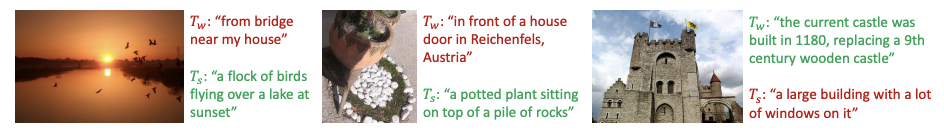

# 5.LLaVA

https://arxiv.org/pdf/2304.08485

![image.png](vision-understanding-concept2.svg)

<font color="red" size="6">最简单的模型结构，最清晰的训练过程，最好的效果</font>


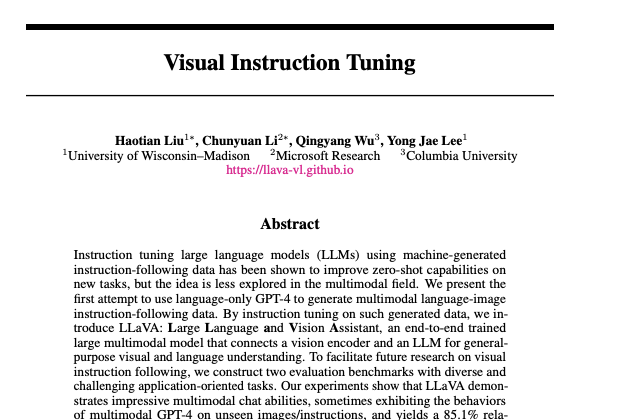

![image.png](llava-diagram.svg)

# 5.1 数据增强

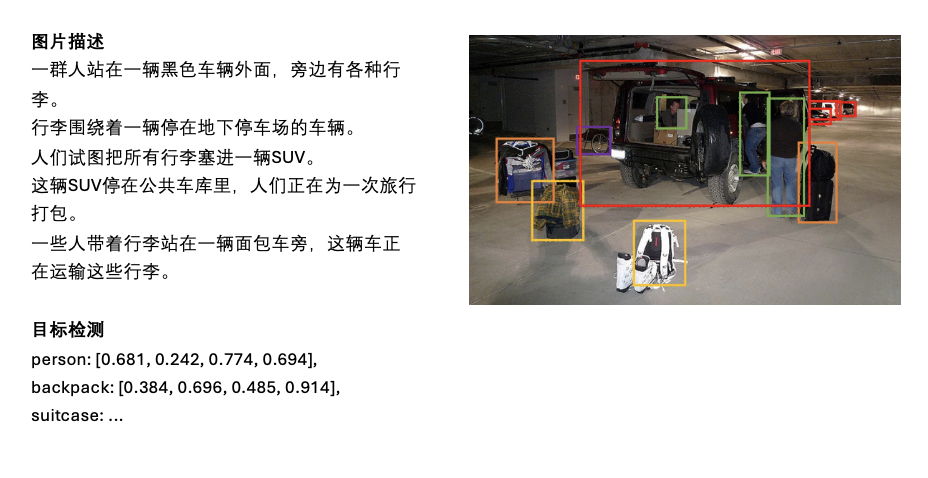

### 如果只是问图片的内容描述了什么，那这个数据已经足够了，但是如果问图片里有几个人，这个是一辆什么车，里面人是出门还是旅行回来？那么这个数据去训练时完全不够的


In [380]:
fewshot_samples=[]
query=''

messages = [
    {"role": "system", "content": f"""你是一个 AI 视觉助手，正在查看一张图片。你所看到的内容通过五句话子来描述，
    所有句子描述的是同一张图片。请回答所有问题，仿佛你正在看着图片并回答问题。这个一问多答问题之间的对话，提问者问的问
    题将根据图片内容。回答应该以视觉 AI 助手正在查看并且回答问题的语气来进行。提问时包含一些多样化的问题，并给出相应
    的回答，包括一些关于图片内容的问题，比如物体的类型、物体的数量、物体的方位、物体之间的相对位置等。只包括可以确定有
    明确答案的问题：
（1）问题的内容在图片中可以看到，并且能够确信地回答；
（2）可以从图片中自信地确认没有该内容。不要问任何无法自信回答的问题。

还可以包括一些复杂的问题，确保这些问题与图片的内容相关，例如，询问图片中物体的背景知识，或者询问图片中发生的事件等。
再次强调，不要问任何不确定的细节。在回答复杂问题时，要提供详细的答案。例如，给出详细的示例或推理步骤，使内容更加令人
信服和有条理。如果有必要，可以包含多个段落。"""}
]

for sample in fewshot_samples:
    messages.append({"role": "user", "content": sample['context']})
    messages.append({"role": "assistant", "content": sample['response']})

messages.append({"role": "user", "content": '\n'.join(query)})


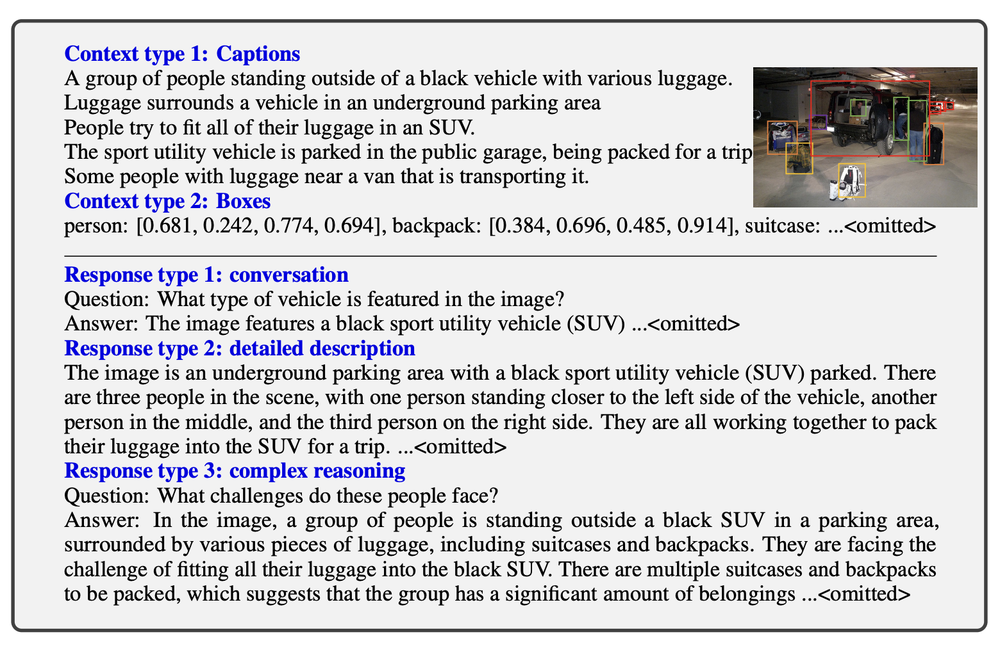

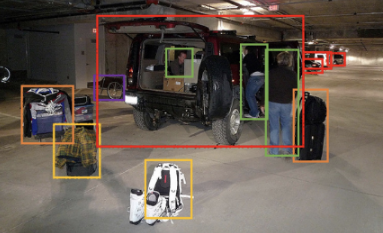

## 对话

**问题：** 图片中的车辆是什么类型的？  
**回答：** 图片中展示的是一辆黑色的 SUV。

**问题：** 车辆停在哪里？  
**回答：** 车辆停在一个地下停车场，可能是一个公共车库。

**问题：** 图片中的人们在做什么？  
**回答：** 这些人正在努力将所有行李放进 SUV 里，可能是在为一次旅行做准备。

---

## 详细描述

这张图片展示了一个地下停车场，里面停着一辆黑色的运动型多功能车（SUV）。场景中有三个人，一个人站在车辆左侧稍近的地方，另一个人站在中间，第三个人则站在右侧。他们正一起努力将行李装进 SUV，为旅行做准备。在停车场中，各种行李散布在车辆周围。两只背包分别放在左后轮附近和靠近车辆右侧的地方。此外，还有两只行李箱，一只位于车辆右侧，另一只则放在车辆中央较远的位置。左侧还可以看到一辆自行车。车辆周围停着其他几辆车，一辆车停在 SUV 的后方并稍微偏左，另一辆车停在它的右后方，还有第三辆车停在更远的右侧。

---

## 复杂推理

**问题：** 这些人面临什么挑战？  
**回答：** 在这张图片中，一群人站在一辆黑色 SUV 的外面，周围有各种行李，包含行李箱和背包。他们面临的挑战是如何将所有行李装进这辆 SUV。行李种类与数量众多，暗示着这群人携带了相当多的物品需要安置。他们可能需要策划略性地安排行李，以确保所有物品都能适当地放进车里。此外，他们还需要考虑乘客的舒适度和驾驶视线，所以行李的摆放必须避免遮挡驾驶员的视角或者使乘客在旅行中感到不适。


## **对话 (58K)**  **详细描述 (23K)**  **复杂推理 (77K)**  **共 158K**


# 5.2 模型结构-大道至简

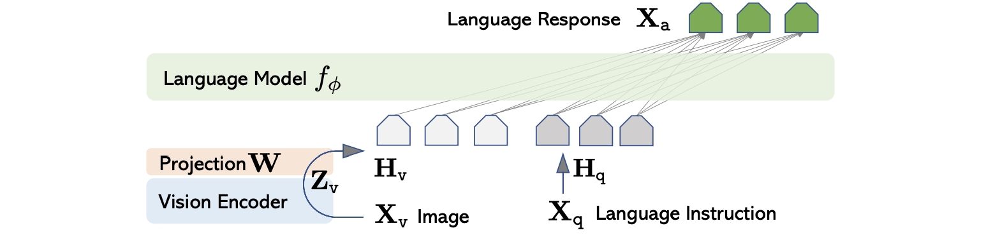

# 两阶段训练

## 阶段 1：特征对齐的预训练(此时没有指令的部分)

- 冻结视觉编码器和 LLM，仅训练线性投影层。
- CC3M 数据集筛选至 595K 对图像-文本对。
- 简单描述图片问答。

## 阶段 2：端到端微调

- 冻结视觉编码器，训练线性投影层和 LLM。
- GPT-4 生成的 158K 视觉指令跟随数据。




##  **训练数据格式说明**

每个训练样本由一个图像 `Xv` 和一个多轮对话 `[(X1q, X1a), (X2q, X2a), ..., (XTq, XTa)]` 组成。

- `Xtq` 是第 t 轮的用户提问（instruction）。
- `Xta` 是模型生成的回答（assistant response）。
- 第一轮的输入 `X1instruct` 是 `[X1q, Xv]` 或 `[Xv, X1q]` 随机选（也就是问和图像的顺序可以打乱）。
- 后续轮次的 `Xt instruct` 就直接用 `Xtq`。

训练时，输入是按如下格式拼接成的单个序列（如下是两轮的例子）：

```
Xsystem-message <STOP>
Human: X1instruct <STOP> Assistant: X1a <STOP>
Human: X2instruct <STOP> Assistant: X2a <STOP>
...
```

其中 `<STOP>` 是特殊标记，用于分隔不同的内容（如Vicuna用 `###`），模型学会在这些位置停止。

---

## **训练目标 (公式 3)**

模型是一个标准的自回归语言模型，训练目标是最大化回答部分 `Xa` 的生成概率：

$$[
p(X_a | X_v, X_{\text{instruct}}) = \prod_{i=1}^{L} p_\theta(x_i | X_v, X_{\text{instruct}, <i}, X_{a,<i})
]$$

简单说，就是让模型根据前面所有内容（图像 + 指令 + 已经生成的答案）来预测当前 token 的概率。

---

## **Stage 1：Feature Alignment（特征对齐预训练）**

目标：训练一个**视觉投影层** W，把图像特征 `Hv` 映射到可以被 LLM 接受的词向量空间，起到桥接作用。

- 数据来源：CC3M 图文对数据集（筛选后剩下约 595K 个）。
- 训练方式：
  - 图像 `Xv` 搭配一个自动生成的问题 `Xq`（例如“请简要描述这张图”），形成一轮对话。
  - `Xa` 是图像原本的 caption。
  - **冻结**视觉编码器和LLM，仅训练投影矩阵 `W`。
  - 相当于构建一个“视觉 tokenizer”。

> ✅ 目的：先让图像特征能对齐到语言模型的语义空间，再进行后续微调。

---

## **Stage 2：Fine-tuning End-to-End（端到端微调）**

目标：让整个系统变得可用，开始对真实任务进行训练，训练的参数包括 `W`（投影层）和 `ϕ`（LLM权重）。

- **视觉编码器仍然冻结**（因为通常是大型预训练模型，太大了）。
- 两种使用场景：

### 1. Multimodal Chatbot（多模态聊天机器人）

- 使用 158K 条图文对话数据（包括三种类型：单轮问答、图像描述、多轮对话）。
- 所有数据统一组织为 instruction + answer 格式。
- 训练时统一抽样不同类型的数据。

### 2. Science QA（科学问答任务）

- 使用 ScienceQA 数据集：问题有图像或文本上下文，回答需要解释过程。
- 数据组织为：
  - 输入 `Xinstruct` 是问题 + 上下文（文本或图像）
  - 输出 `Xa` 是推理过程 + 正确答案。
  - 训练为 **单轮对话格式**。

---

## 总结重点

| 阶段 | 目标 | 数据 | 是否冻结视觉编码器 | 训练的参数 |
|------|------|------|------------------|-------------|
| Stage 1 | 特征对齐 | CC3M (图文描述) | 是 | 投影矩阵 W |
| Stage 2 | 多模态指令微调 | 多轮对话 + ScienceQA | 是 | W + LLM权重 |

---


# 5.3 结果评估

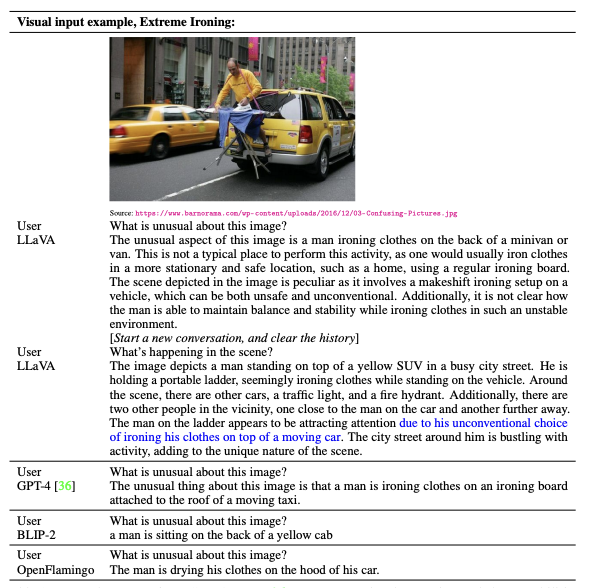

## 5.4 LLaVA 1.5

### 5.4.1 更小的模型，更少的数据达到了更好的效果

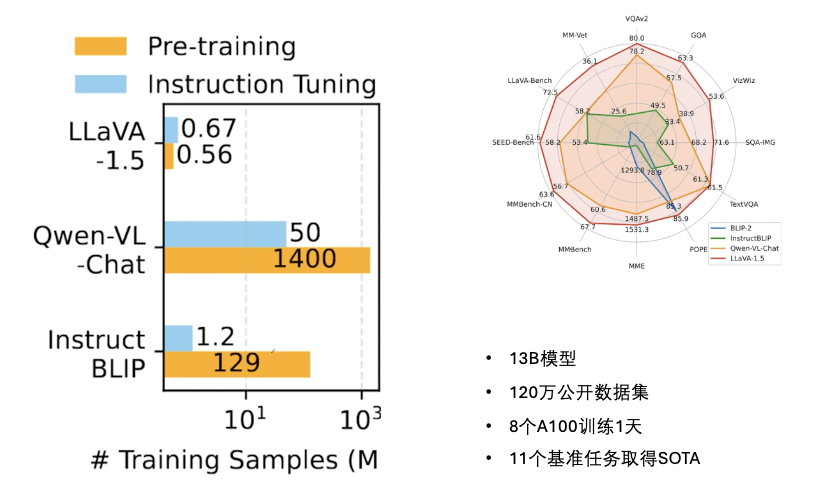

### 5.4.2 模型层的改进

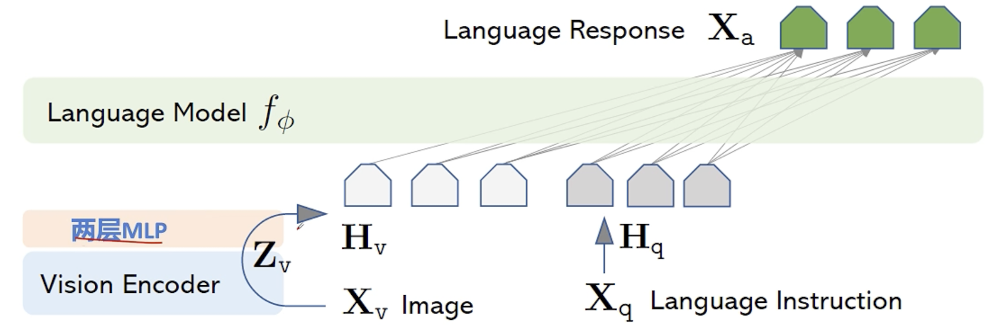

### 5.4.3 数据的改进

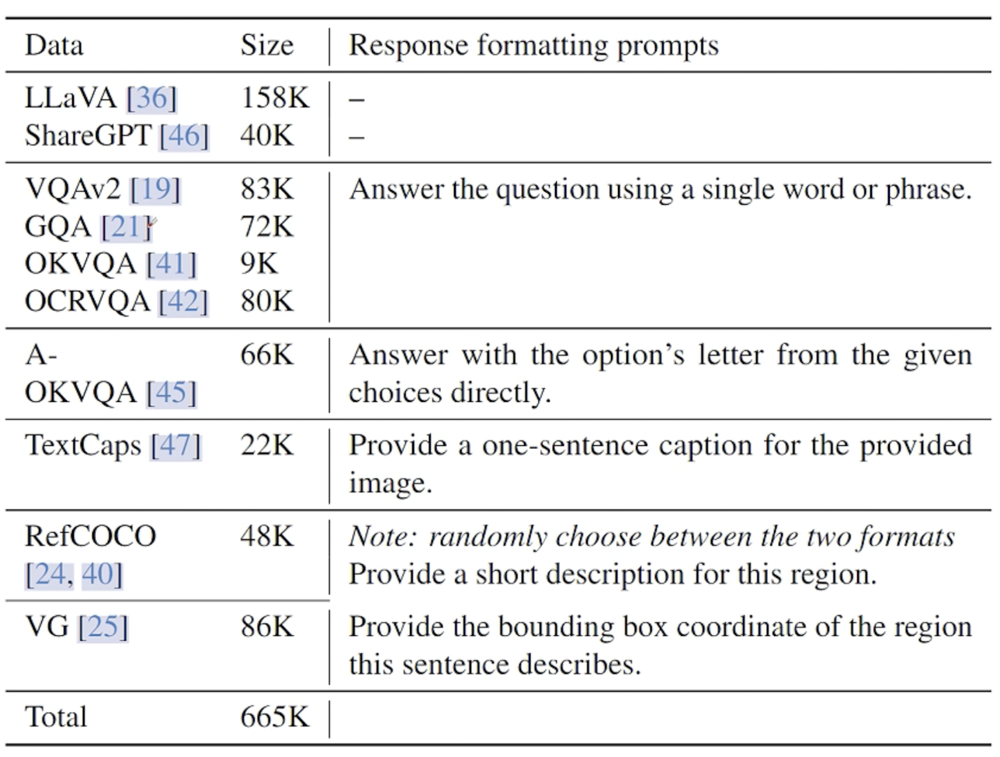

### 5.4.4 图像提高分辨率

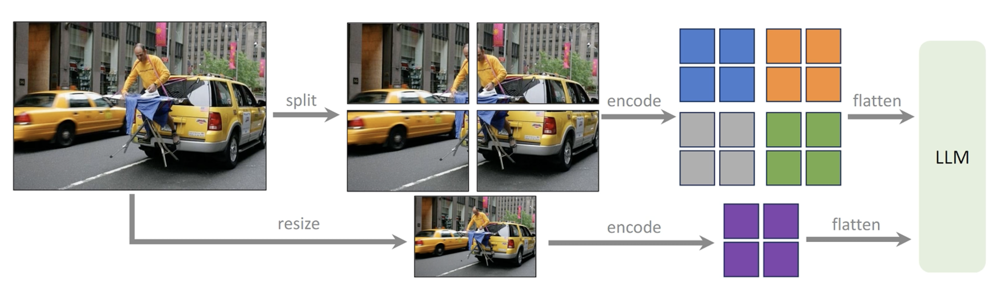